In [25]:
using LinearAlgebra
using DifferentialEquations, Plots
using BenchmarkTools
using HypothesisTests
default(grid=false,legend=false, size=(400,320), dpi=300, tickfontsize=16, lw=2, lc=:gray, labelfontsize=16, tickdir=:out, fontfamily="Arial", legendfontsize=13, markercolor=:indianred)

mydir = "../helper/"
include(mydir * "base.jl")
include(mydir * "optimization.jl")
include(mydir * "misc.jl")
include(mydir * "myplot.jl")

plot_histogram (generic function with 1 method)

### Load data

In [2]:
using DelimitedFiles
# INSERT YOUR OWN DATA DIRECTORY AND FILENAME HERE
# E. coli MG1655 (CGSC 6300)/20090131/xy01c1/ch1_cell0.dat
data_dir = "/Volumes/Chenyi/MIT/research/Cell_growth/data/CurrBiol10/E_coli_MG1655/"
DT = 1/60; # convert to hours
DL = 0.0645; # convert to um

In [3]:
# # manual selection

# data_date = "20090131/"
# data_fov = "xy14c1/"
# filename_all = readdir(data_dir*data_date*data_fov);
# select_cache = filename_all[ contains.(filename_all, "_cell0.dat") ]

# idx=1
# tab_cache=readdlm(data_dir * data_date * data_fov * select_cache[idx]);
# varnames = convert(Vector{String}, tab_cache[1,:]);
# tt = tab_cache[2:end,findfirst(varnames .== "index")] * DT;
# LL = tab_cache[2:end,findfirst(varnames .== "length")] * DL;
# data_date * data_fov * select_cache[idx]
# tmp = [(0,50.0)]
# pp = plot(tt, LL, size=(1500,300),bottommargin=7Plots.mm, leftmargin=5Plots.mm)
# for i in eachindex(tmp)
#     plot!(pp, tt[ (tt.>tmp[i][1]) .& (tt .< tmp[i][2]) ], LL[(tt.>tmp[i][1]) .& (tt .< tmp[i][2])],lc=:indianred)
# end

In [5]:
# INSERT SELECTED FILES AND TIME WINDOWS HERE.

select_filename =[
    "20090131/xy01c1/ch0_cell0.dat",
    "20090131/xy01c1/ch1_cell0.dat",
    "20090131/xy01c1/ch2_cell0.dat",
    "20090131/xy01c1/ch3_cell0.dat",
    "20090131/xy01c1/ch4_cell0.dat",
    "20090131/xy01c1/ch5_cell0.dat",
    "20090131/xy01c1/ch6_cell0.dat",
    "20090131/xy02c1/ch0_cell0.dat",
    "20090131/xy03c1/ch0_cell0.dat",
    "20090131/xy04c1/ch0_cell0.dat",
    "20090131/xy04c1/ch1_cell0.dat",
    "20090131/xy05c1/ch0_cell0.dat",
    "20090131/xy05c1/ch1_cell0.dat",
    "20090131/xy05c1/ch2_cell0.dat",
    "20090131/xy05c1/ch3_cell0.dat",
    "20090131/xy06c1/ch0_cell0.dat",
    "20090131/xy06c1/ch1_cell0.dat",
    "20090131/xy06c1/ch2_cell0.dat",
    "20090131/xy06c1/ch3_cell0.dat",
    "20090131/xy07c1/ch0_cell0.dat",
    "20090131/xy07c1/ch1_cell0.dat",
    "20090131/xy07c1/ch2_cell0.dat",
    "20090131/xy07c1/ch3_cell0.dat",
    "20090131/xy07c1/ch4_cell0.dat",
    "20090131/xy07c1/ch5_cell0.dat",
    "20090131/xy08c1/ch0_cell0.dat",
    "20090131/xy08c1/ch1_cell0.dat",
    "20090131/xy08c1/ch2_cell0.dat",
    "20090131/xy08c1/ch3_cell0.dat",
    "20090131/xy08c1/ch4_cell0.dat",
    "20090131/xy09c1/ch0_cell0.dat",
    "20090131/xy09c1/ch1_cell0.dat",
    "20090131/xy09c1/ch2_cell0.dat",
    "20090131/xy09c1/ch3_cell0.dat",
    "20090131/xy10c1/ch0_cell0.dat",
    "20090131/xy10c1/ch1_cell0.dat",
    "20090131/xy10c1/ch2_cell0.dat",
    "20090131/xy11c1/ch0_cell0.dat",
    "20090131/xy12c1/ch0_cell0.dat",
    "20090131/xy12c1/ch1_cell0.dat",
    "20090131/xy12c1/ch2_cell0.dat",
    "20090131/xy12c1/ch3_cell0.dat",
    "20090131/xy12c1/ch4_cell0.dat",
    "20090131/xy12c1/ch5_cell0.dat",
    "20090131/xy12c1/ch6_cell0.dat",
    "20090131/xy12c1/ch7_cell0.dat",
    "20090131/xy13c1/ch0_cell0.dat",
    "20090131/xy13c1/ch1_cell0.dat",
    "20090131/xy13c1/ch2_cell0.dat",
    "20090131/xy14c1/ch0_cell0.dat",
]

select_time_all = [
    [(0.0, 11.0), (12.6, 26.8), (33.3, 46.8), (51.6, 60.8)],
    [(0.0, 20.8), (21.6, 34.3)],
    [(0.0, 24.0),(27.0,46.0)],
    [(52.,65.0)],
    [(58.,65.0)],
    [(51.5,64.0)],
    [(53.0,64.3)],
    [(0.0,18.55), (19.5,31.0)],
    [(0.0,29.5)],
    [(0.0,16.0), (21.0, 43.0)],
    [(0.0,4.0), (5.0, 21.8), (26.5,46.0)],
    [(0.0,8.5), (9.5, 32.8)],
    [(0.0,25.5), (26.2, 32.5)],
    [(0.0,20.1)],
    [(55.0,65.0)],
    [(0.0,13.5),(18.5,34.0)],
    [(0.0,27.9)],
    [(0.0,19.0),(22.5,34.5)],
    [(48.0,65.0)],
    [(0.0,14.2),(15.5,30.5)],
    [(0.0,12.5),(13.3,19.2),(22.0,48.0),(50.0,60.5)],
    [(1.3,22.0),(25.5,49.8),(52.5,65.0)],
    [(37.0,54.0)],
    [(40.2,61.0)],
    [(50.0,64.5)],
    [(0.0,40.5),(41.8,55.2)],
    [(0.0,39.5)],
    [(0.0, 21.0),(24.2,40.0)],
    [(48.0,65.0)],
    [(62.0,65.0)],
    [(4.5, 34.5), (36.5,56.0)],
    [(0.0,40.0)],
    [(0.0,4.3),(5.3,13.0),(13.5,44.0),(46.0,61.6)],
    [(58.0,65.0)],
    [(2.2,22.0)],
    [(0.0,18.5),(37.0,54.0)],
    [(58.0,65.0)],
    [(1.3,38.0)],
    [(0.,24.0),(31.0,39.4),(42.3,60.0)],
    [(41.5,65.0)],
    [(43.0,64.5)],
    [(43.6,65.0)],
    [(50.0,65.0)],
    [(44.0,65.0)],
    [(50.0,65.0)],
    [(50.0,65.0)],
    [(0.1,7.0),(8.2,43.4)],
    [(39.0,44.8),(50.4,63.6)],
    [(53.5,60.0)],
    [(0.0,50.0)]
]

# annotate
Lobs_ = []
tobs_ = []
for idx in eachindex(select_filename)
    tab = readdlm(data_dir * select_filename[idx]);
    varnames = convert(Vector{String}, tab[1,:]);
    tobs = tab[2:end,findfirst(varnames .== "index")] * DT;
    Lobs = tab[2:end,findfirst(varnames .== "length")] * DL;
    Lobs_idx, tobs_idx = filter_exp_traj(Lobs, tobs; select_time = select_time_all[idx] );
    Lobs_ = vcat(Lobs_, Lobs_idx)
    tobs_ = vcat(tobs_, tobs_idx)
end
Lobs_ = convert.(Vector{Float64}, Lobs_);
tobs_ = convert.(Vector{Float64}, tobs_);


In [6]:
(size(select_filename) == size(select_time_all)) && (@show size(select_filename);)


size(select_filename) = (50,)


(50,)

In [7]:
isdiv_, dtobs_ = annotate_exp_traj(Lobs_, tobs_);

In [8]:
n_func = 11;
basis_func = Polynomial()
Θ, Σ = gen_ortho_bases(vcat(Lobs_...), n_func-1);
# _, Σ = gen_ortho_bases(collect(0.:0.01:15.0), n_func-1, basis_func);
# Θ = gen_ortho_bases(vcat(Lobs_...), Σ, basis_func);
Θdiv = Θ[vcat(isdiv_...),:];
Θdiv = sum(Θdiv, dims=1)[:];

In [9]:
# _, coeffs_sparse = sparse_optimization(Θ, Θdiv, vcat(dtobs_...); EPSILON=1E-7, MAX_ITERS=40);

In [10]:
history = sparse_optimization_sweep(Θ, Θdiv, vcat(dtobs_...); EPSILON=1E-5, MAX_ITERS=20);

===== start of epoch 1 =====


itr=1: -3919.178826806887


itr=2: -3918.648448631806


itr=3: -3918.2202020048308


itr=4: -3917.977934031323


itr=5: -3917.8371567633394


... (59 outputs left out)

itr=3: -3606.604655095504
===== end of epoch 5 =====
error = -2.593408882894875, nterms = 2, cutoff = 0.33449123806090014
===== start of epoch 6 =====
itr=1: -3606.244894382506


itr=2: -3606.604984563471
itr=3: -3606.604655095504
itr=1: -1956.0053710844682
itr=2: -1955.8584276032745
itr=3: -1955.858413962695


itr=1: -1956.0053710844682
itr=2: -1955.8584276032745
itr=3: -1955.858413962695
===== end of epoch 6 =====
error = -1.406372865400193, nterms = 1, cutoff = 0.5527928167608986
===== start of epoch 7 =====
itr=1: -1956.0053710844682


itr=2: -1955.8584276032745
itr=3: -1955.858413962695
===== end of epoch 7 =====
error = 0.9999999999992704, nterms = 0, cutoff = 0.8402924580446008


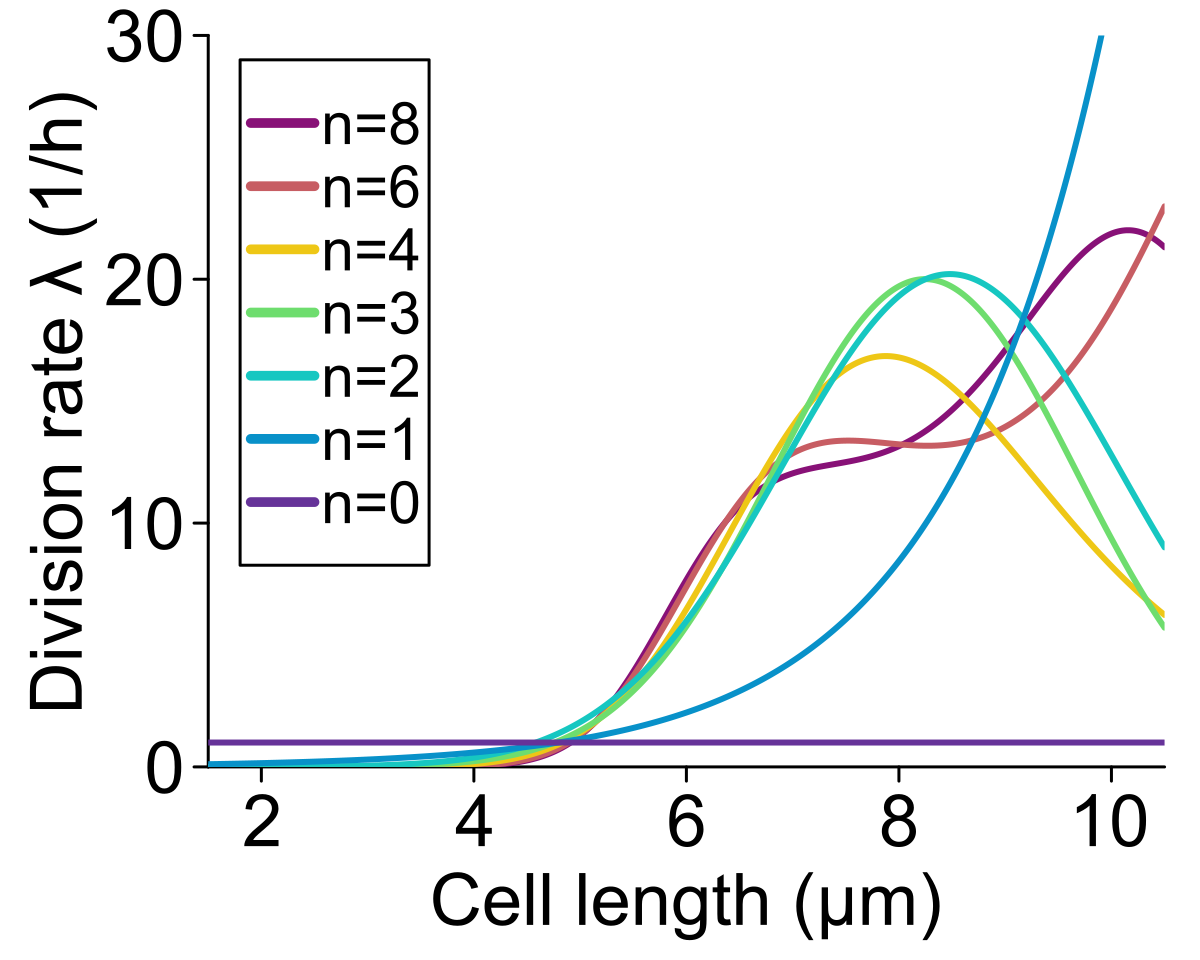

In [12]:
uu = collect(1.5:0.01:10.5);
p2 = plot(;legend=true, ylim=(0,30), ytick=collect(0:10:40), xlim=(1.5, 10.5), xtick=collect(2:2:10), ylabel="Division rate λ (1/h)", xlabel="Cell length (μm)")

history_cl = palette(:twelvebitrainbow, length(history[:coeffs]))
for i in 1:length(history[:coeffs])
    logλ_sparse = rec_ortho_bases(uu, Σ, history[:coeffs][i]);
    plot!(p2, uu, exp.(logλ_sparse), label="n=$(history[:nterms][i])", lc=history_cl[i])
end
p2

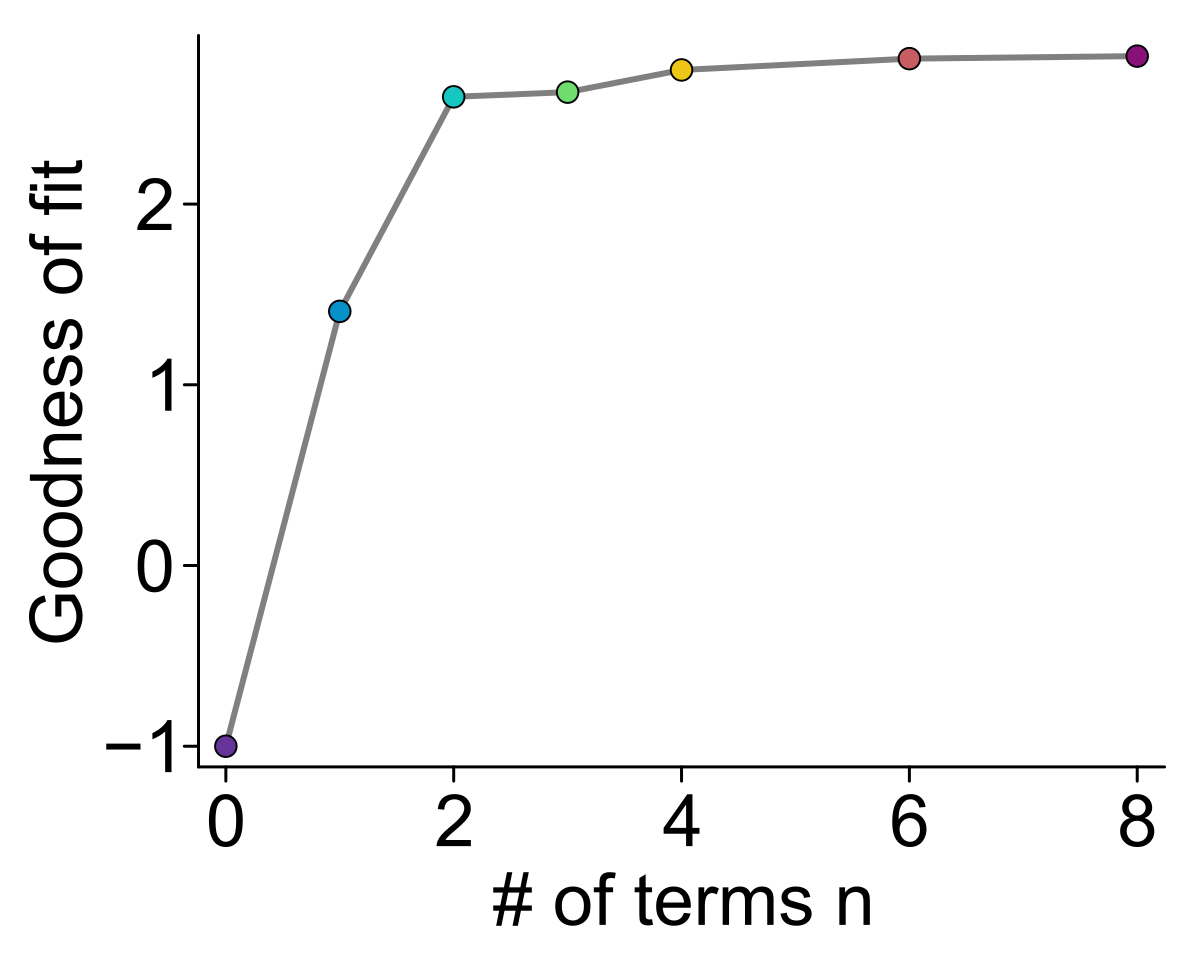

In [13]:
p3 = plot(; ylabel="Goodness of fit", xlabel="# of terms n")
plot!(p3, history[:nterms], -history[:error])
scatter!(p3, history[:nterms], -history[:error]; zcolor=collect(1:length(history[:nterms])), mc=:twelvebitrainbow)

# savefig("nterm_vs_gof.pdf")

In [14]:
# 2023-08-24: fitting with tanh
using StatsBase
hedges = collect(3:0.35:10.0);
hbins = 0.5*( hedges[1:end-1] + hedges[2:end] )
dhedges = mean( diff(hedges) );

h1_obs = fit(Histogram, vcat( [Lobs_[i][isdiv_[i]] for i in eachindex(Lobs_) ]...), hedges)
h1_obs_normalize = h1_obs.weights / sum(h1_obs.weights) / dhedges

20-element Vector{Float64}:
 0.0
 0.002212552548123018
 0.004425105096246036
 0.01106276274061509
 0.034663323253927285
 0.09366472453720777
 0.24780588538977802
 0.35990854782801096
 0.49118666568331
 0.45652334242938275
 0.31565749686555056
 0.26698134080684416
 0.16815399365734937
 0.1482410207242422
 0.08112692676451067
 0.06416402389556752
 0.04277601593037835
 0.033925805737886276
 0.019175455417066157
 0.015487867836861126

In [15]:
function tanh_rate(l::T, params::Vector{T}) where T
    g = params[1]
    β = params[2]
    la = params[3]
    w = params[4]
    
    y = g*β*(1+tanh((l-la)/w))/2
    
    return y
end

tanh_rate (generic function with 1 method)

In [ ]:
# # fitting the growth rate
# Y_f = vcat( [ (Lobs_[i][2:end] .- Lobs_[i][1:end-1]) ./ (tobs_[i][2:end] .- tobs_[i][1:end-1])  for i in eachindex(Lobs_)]... );
# Lt_f =  vcat( [Lobs_[i][1:end-1] for i in eachindex(Lobs_) ]... );
# Lt_f = Lt_f[abs.(Y_f) .< 50.0]; Y_f = Y_f[abs.(Y_f) .< 50.0];
# Theta_f = gen_bases( Lt_f,  1);

In [16]:
function f(du, u, p, t)
    du[1] = p[1]*u[1]
end

function rate(u,p,t) 
    g = p[1]
    β = p[2]
    la = p[3]
    w = p[4]
    return g*β*(1+tanh((u[1]-la)/w))/2
end

function affect!(integrator)
    integrator.u[1] /= 2
end

u0 = [2.5]
vrj = VariableRateJump(rate, affect!)
oprob = ODEProblem(f, u0, (0.0,1000.0), (1.88,  6.75, 5.8, 0.7) )
jprob = JumpProblem(oprob, Direct(), vrj)
sol = solve(jprob,Tsit5(),dtmax=0.01);

Lsim = Array(sol')[:,1];
tsim = sol.t;
isdiv_sim, _ = annotate_sim_traj(Lsim, tsim);

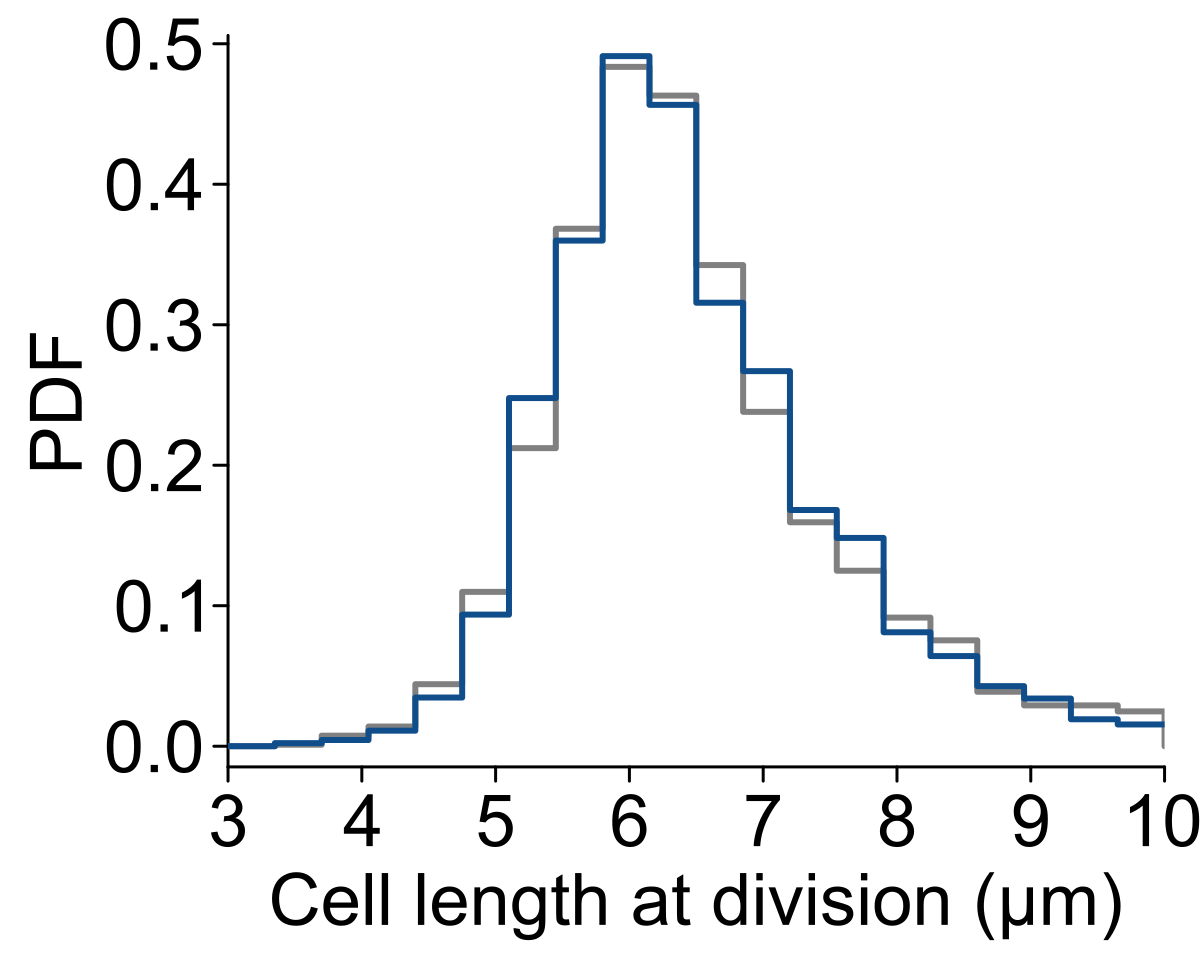

In [22]:
pp1 = stephist(Lsim[isdiv_sim], normalize=:pdf, bins=(3:0.35:10), xlim=(3,10),xlabel="Cell length at division (μm)", ylabel="PDF")
plot_histogram!(pp1, hedges, h1_obs_normalize; lc=:dodgerblue4)
pp1
# savefig(pp1,"ld_pdf.pdf")

In [19]:
ll = collect(2:0.01:10)
λλ = zeros(length(ll));
for i in eachindex(λλ)
    λλ[i] = rate(ll[i], (1.88,  6.75, 5.8, 0.7),0.0)
end

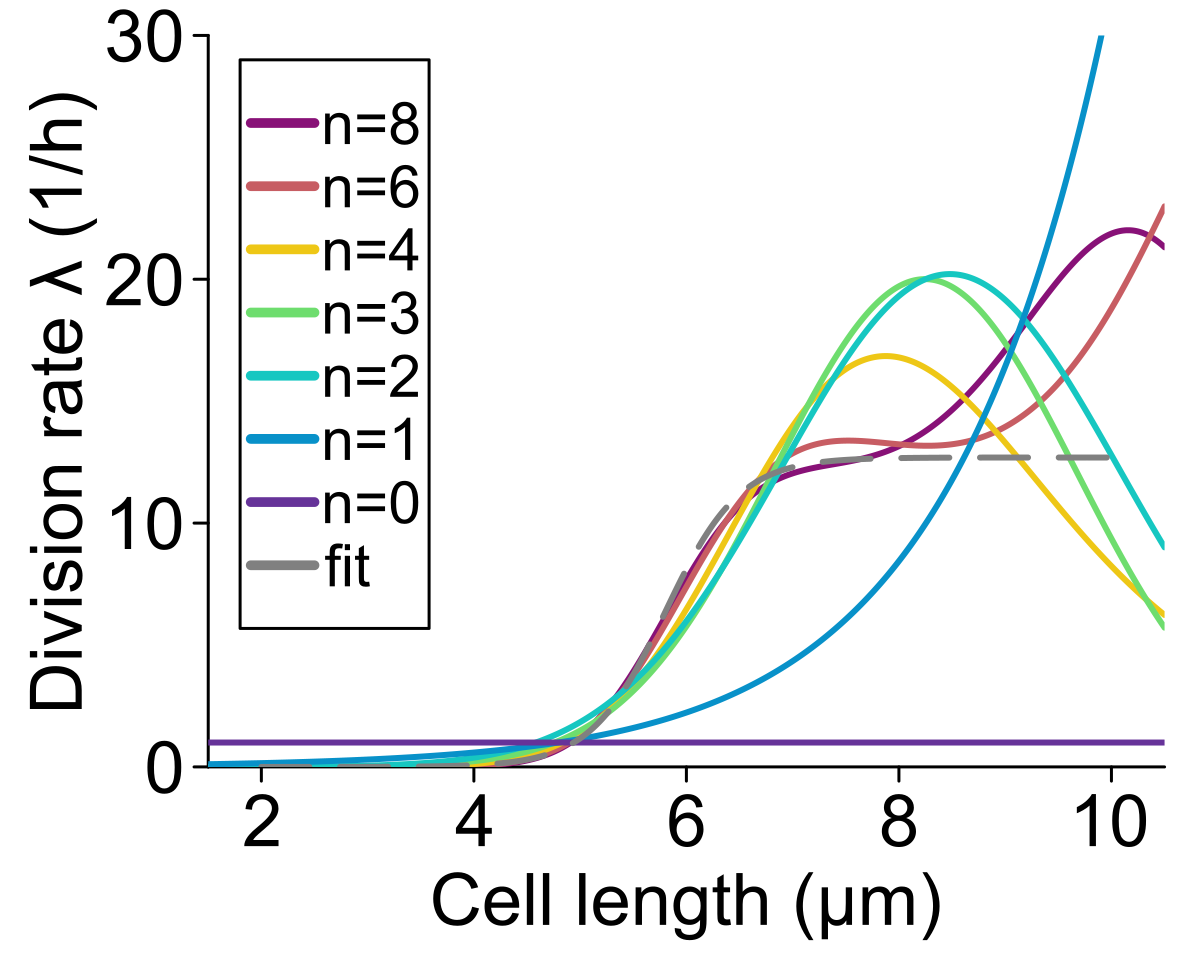

In [20]:
plot!(p2, ll, λλ, ls=:dash, label="fit")
# savefig(p2,"inferred_lambda.pdf")

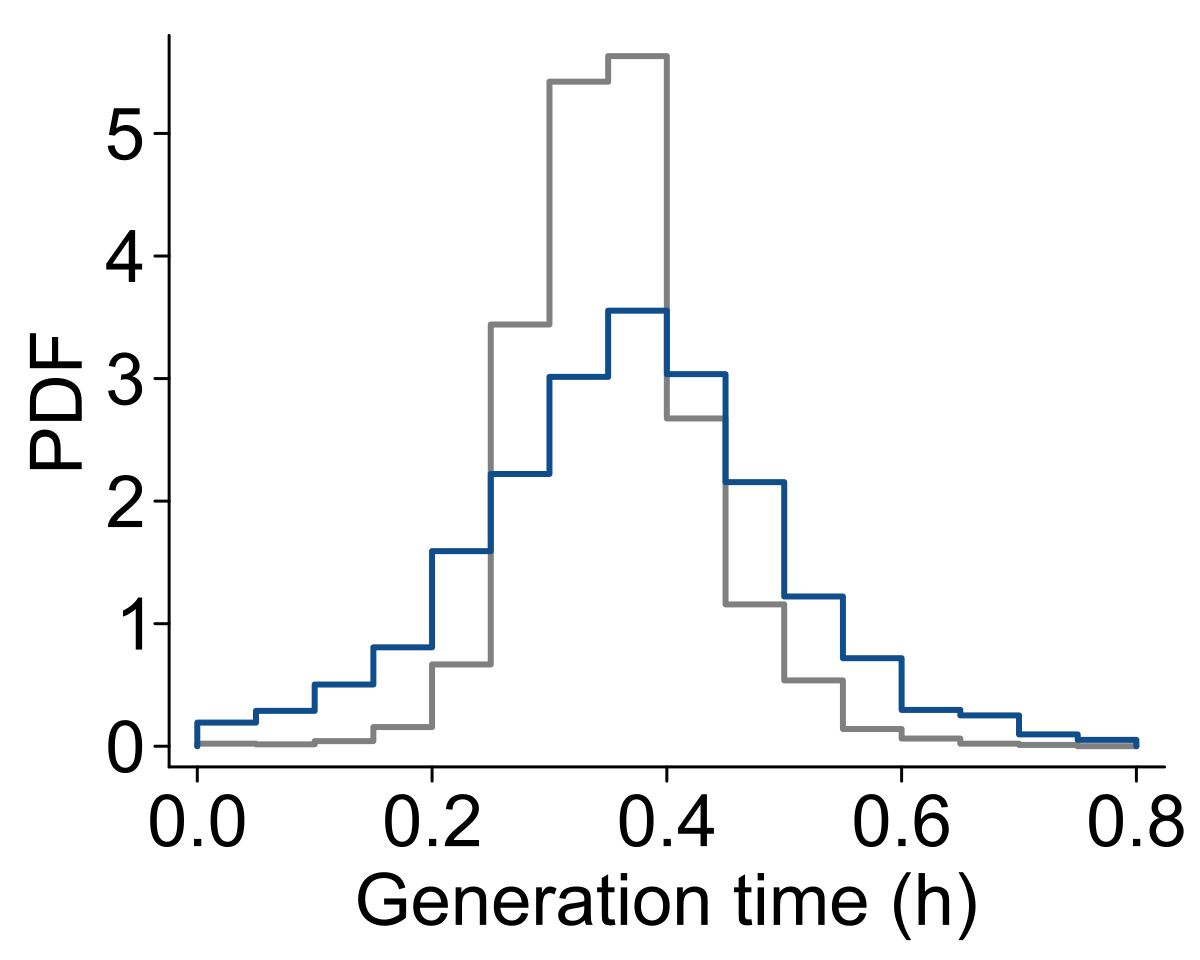

In [23]:
stephist(vcat( diff.([tobs_[i][isdiv_[i]] for i in eachindex(tobs_)]) ... ), bins=collect(0:0.05:0.8), normalize=:pdf, ylabel="PDF", xlabel="Generation time (h)")
stephist!(diff(tsim[isdiv_sim]), bins=collect(0:0.05:0.8), normalize=:pdf,lc=:dodgerblue4)

In [27]:
# compute covariance

nn = collect(0:20)
cov_exp = zeros(length(nn))
cov_sim = zeros(length(nn))

for i in eachindex(nn)
    cov_exp[i] = compute_ldiv_cov(Lobs_, isdiv_, nn[i]);
    cov_sim[i] = compute_ldiv_cov(Lsim, isdiv_sim, nn[i]);
end

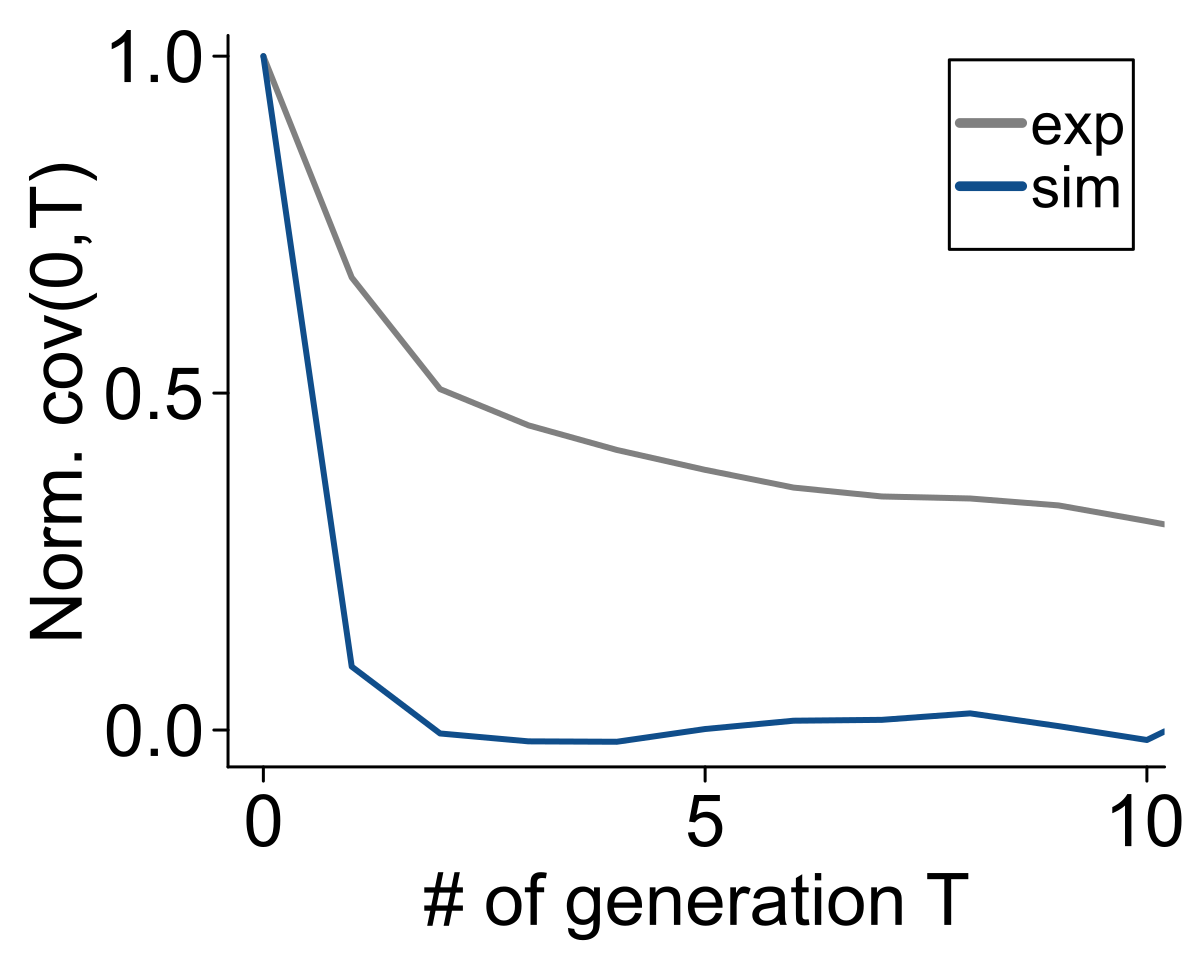

In [31]:
plot(nn, cov_exp./cov_exp[1], legend=true, label="exp", xlim=[-0.4,10.2],xtick=[0,5,10],ytick=[0,0.5,1], ylabel="Norm. cov(0,T)", xlabel="# of generation T")
plot!(nn, cov_sim./cov_sim[1], lc=:dodgerblue4, label="sim")
# savefig("cov_ld.pdf")